In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"C:\Users\HP\Downloads\social_media_engagement_5000.csv")

print(df.head())

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  Female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    Male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  Female      UK   109864      text          food   4862.0   
3    64886  51.0   Other  France   848877      text       fitness   5350.0   
4    16265  34.0   Other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count   posted_at  \
0     354.0  1157.0            5726             44650  17-12-2022   
1    2606.0  1807.0            5947             80216  02-06-2023   
2     344.0   955.0            6946             44858  07-05-2023   
3    1083.0  1049.0             229             70455  12-02-2023   
4    2735.0  1300.0            4798              6019  23-05-2023   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      m

In [3]:
print(df.dtypes)

user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object


In [4]:
df["posted_at"] = pd.to_datetime(df["posted_at"], dayfirst=True)

In [5]:
print(df.dtypes)

user_id                      int64
age                        float64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
dtype: object


In [6]:
# Check for missing values
print("Missing values:")
print(df.isnull().sum())

Missing values:
user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [7]:
# Fill numerical missing values with median

num_cols = ["age", "likes", "comments", "shares"]

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())


# Fill categorical missing values with mode

cat_cols = ["gender", "sentiment"]

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])


# Check missing values again
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [8]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [9]:
df["gender"] = df["gender"].str.strip().str.lower().str.title()

print(df["gender"].value_counts())

gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64


In [10]:
print("Negative likes:", (df["likes"] < 0).sum())
print("Negative comments:", (df["comments"] < 0).sum())
print("Negative shares:", (df["shares"] < 0).sum())

Negative likes: 0
Negative comments: 0
Negative shares: 0


In [11]:
df["hashtag_count"] = df["hashtags"].fillna("").apply(lambda x: len(x.split()))

print(df[["hashtags", "hashtag_count"]].head())

                hashtags  hashtag_count
0  #foodie #travel #love              3
1               #fitness              1
2                #foodie              1
3    #music #foodie #fun              3
4                #travel              1


In [12]:
df["sentiment"] = df["sentiment"].str.strip().str.lower().str.title()

print(df["sentiment"].value_counts())


sentiment
Positive    2513
Neutral     1527
Negative     960
Name: count, dtype: int64


In [13]:
print(df.head())
print(df.tail())
print("Shape:", df.shape)
print("Columns:", df.columns)

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  Female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    Male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  Female      UK   109864      text          food   4862.0   
3    64886  51.0   Other  France   848877      text       fitness   5350.0   
4    16265  34.0   Other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count  posted_at  \
0     354.0  1157.0            5726             44650 2022-12-17   
1    2606.0  1807.0            5947             80216 2023-06-02   
2     344.0   955.0            6946             44858 2023-05-07   
3    1083.0  1049.0             229             70455 2023-02-12   
4    2735.0  1300.0            4798              6019 2023-05-23   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      mobile 

In [14]:
df.info()

print(df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [15]:
print(df.describe())

            user_id          age        post_id         likes     comments  \
count   5000.000000  5000.000000    5000.000000   5000.000000  5000.000000   
mean   54561.890800    38.440400  548042.909000  10106.997400  1502.039800   
min    10055.000000    13.000000  100068.000000     10.000000     0.000000   
25%    32309.500000    26.000000  322543.500000   5235.000000   792.000000   
50%    54374.500000    38.000000  548077.500000  10105.500000  1497.000000   
75%    77180.500000    51.000000  771574.500000  14959.000000  2235.250000   
max    99963.000000    64.000000  999455.000000  19998.000000  2999.000000   
std    26090.370121    14.687151  260646.957267   5702.293017   856.393312   

          shares  watch_time_sec  impression_count  \
count  5000.0000     5000.000000       5000.000000   
mean   1002.9106     4014.503200      50013.732800   
min       0.0000        0.000000        105.000000   
25%     511.0000     2017.750000      24988.250000   
50%    1012.0000     4034.5

In [16]:
print(df["gender"].value_counts())
print(df["country"].value_counts())
print(df["post_type"].value_counts())
print(df["sentiment"].value_counts())

print("Unique genders:", df["gender"].unique())
print("Number of unique genders:", df["gender"].nunique())

gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64
sentiment
Positive    2513
Neutral     1527
Negative     960
Name: count, dtype: int64
Unique genders: ['Female' 'Male' 'Other']
Number of unique genders: 3


In [17]:
correlation = df.select_dtypes(include="number").corr()

print(correlation)

                   user_id       age   post_id     likes  comments    shares  \
user_id           1.000000 -0.006688  0.020051  0.025811 -0.033395  0.013763   
age              -0.006688  1.000000 -0.013153 -0.036322 -0.007284  0.013871   
post_id           0.020051 -0.013153  1.000000  0.014526 -0.010540  0.001846   
likes             0.025811 -0.036322  0.014526  1.000000 -0.018421  0.004712   
comments         -0.033395 -0.007284 -0.010540 -0.018421  1.000000  0.006142   
shares            0.013763  0.013871  0.001846  0.004712  0.006142  1.000000   
watch_time_sec   -0.016847  0.005542  0.018374  0.008710 -0.016351  0.014658   
impression_count  0.015326  0.013322 -0.007709  0.007952 -0.009395 -0.005204   
follower_count    0.010124 -0.024894 -0.002844 -0.022982 -0.011733 -0.010783   
engagement_rate  -0.004282  0.008039  0.010139  0.093520  0.000051  0.021724   
hashtag_count    -0.013692  0.007173  0.007344 -0.002190 -0.015230  0.013379   

                  watch_time_sec  impre

In [18]:
print(df.groupby("post_type")["likes"].mean())

post_type
image    10104.865277
reel     10037.802416
text     10100.148193
video    10188.600000
Name: likes, dtype: float64


In [19]:
print(df.groupby("country")["impression_count"].mean())

country
Australia    48346.383367
Brazil       49193.174603
Canada       48703.150097
France       51727.673387
Germany      48605.406122
India        52462.386916
Japan        49616.135593
UAE          48928.413519
UK           51119.393509
USA          51263.872255
Name: impression_count, dtype: float64


In [20]:
print(df.groupby("post_type")[["likes", "comments", "shares"]].mean())

                  likes     comments       shares
post_type                                        
image      10104.865277  1525.235766  1019.289495
reel       10037.802416  1504.187062   982.042089
text       10100.148193  1499.106024  1013.989558
video      10188.600000  1479.160000   996.834286


In [22]:
df["engagement_score"] = (
    df["likes"] + df["comments"] + df["shares"]
)

print(df[["likes", "comments", "shares", "engagement_score"]].head())


     likes  comments  shares  engagement_score
0   7011.0     354.0  1157.0            8522.0
1  11750.0    2606.0  1807.0           16163.0
2   4862.0     344.0   955.0            6161.0
3   5350.0    1083.0  1049.0            7482.0
4  12682.0    2735.0  1300.0           16717.0


In [23]:
print(df.groupby("post_type")["engagement_score"].mean())

post_type
image    12649.390537
reel     12524.031567
text     12613.243775
video    12664.594286
Name: engagement_score, dtype: float64


In [24]:
print(df.groupby("country")["engagement_score"].mean())

country
Australia    12809.621704
Brazil       12385.983135
Canada       12605.894737
France       12903.384073
Germany      12635.664286
India        12492.701869
Japan        12578.648305
UAE          12757.777336
UK           12384.374239
USA          12575.461078
Name: engagement_score, dtype: float64


In [25]:
print(df.groupby("sentiment")["engagement_score"].mean())

sentiment
Negative    12731.498958
Neutral     12448.163720
Positive    12665.799443
Name: engagement_score, dtype: float64


In [27]:
columns = [
    "likes",
    "comments",
    "shares",
    "watch_time_sec",
    "engagement_rate",
    "follower_count"
]

print("Mean:")
print(df[columns].mean())

print("\nMedian:")
print(df[columns].median())

print("\nMode:")
print(df[columns].mode().iloc[0])


Mean:
likes               10106.997400
comments             1502.039800
shares               1002.910600
watch_time_sec       4014.503200
engagement_rate         0.964356
follower_count     393698.224800
dtype: float64

Median:
likes               10105.500000
comments             1497.000000
shares               1012.000000
watch_time_sec       4034.500000
engagement_rate         0.253896
follower_count     388982.000000
dtype: float64

Mode:
likes               10105.500000
comments             1497.000000
shares               1012.000000
watch_time_sec        916.000000
engagement_rate         0.006363
follower_count     497502.000000
Name: 0, dtype: float64


In [28]:
print("Standard Deviation:")
print(df[columns].std())

print("\nVariance:")
print(df[columns].var())

Standard Deviation:
likes                5702.293017
comments              856.393312
shares                570.855200
watch_time_sec       2308.096459
engagement_rate         5.318029
follower_count     230927.884535
dtype: float64

Variance:
likes              3.251615e+07
comments           7.334095e+05
shares             3.258757e+05
watch_time_sec     5.327309e+06
engagement_rate    2.828143e+01
follower_count     5.332769e+10
dtype: float64


In [29]:
print("Percentiles:")
print(df[columns].quantile([0.25, 0.50, 0.75]))

Percentiles:
        likes  comments  shares  watch_time_sec  engagement_rate  \
0.25   5235.0    792.00   511.0         2017.75         0.145781   
0.50  10105.5   1497.00  1012.0         4034.50         0.253896   
0.75  14959.0   2235.25  1483.0         6020.25         0.504794   

      follower_count  
0.25       194480.00  
0.50       388982.00  
0.75       589744.25  


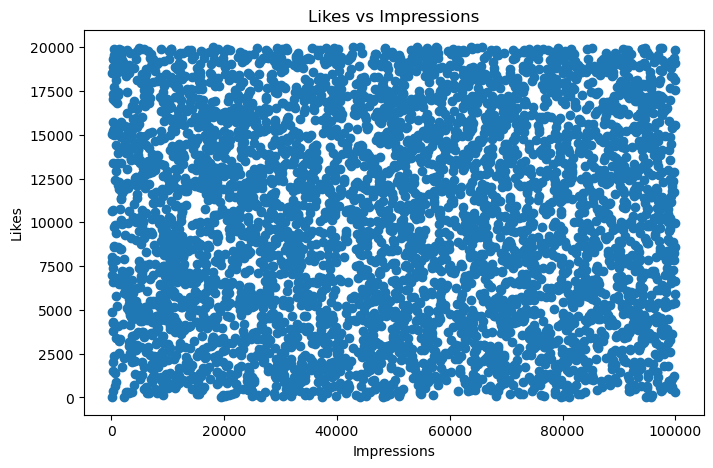

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
plt.scatter(df["impression_count"], df["likes"])
plt.xlabel("Impressions")
plt.ylabel("Likes")
plt.title("Likes vs Impressions")
plt.show()


In [ ]:
# This scatter plot examines the relationship between impressions and likes.The points are widely scattered across the graph rather than following a strong linear pattern.This suggests that higher impressions do not necessarily result in proportionally higher likes.
# Therefore reach alone does not appear to be a strong predictor of likes in this dataset.

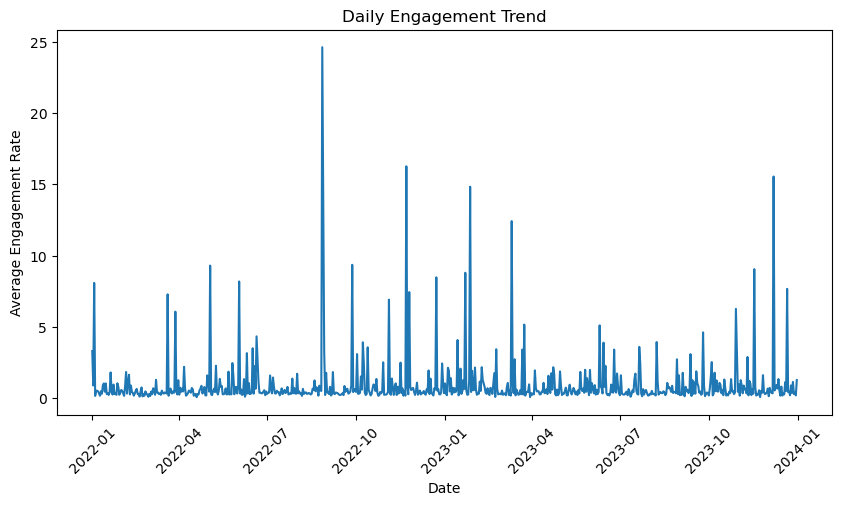

In [31]:
daily_engagement = df.groupby("posted_at")["engagement_rate"].mean()

plt.figure(figsize=(10,5))
plt.plot(daily_engagement.index, daily_engagement.values)
plt.xlabel("Date")
plt.ylabel("Average Engagement Rate")
plt.title("Daily Engagement Trend")
plt.xticks(rotation=45)
plt.show()


In [ ]:
# This line graph shows how average engagement rate changes over time.
# Most days have relatively low and stable engagement rates.
# However several large spikes can be observed throughout the period.
# These spikes indicate that certain posts or periods achieved exceptionally high engagement.


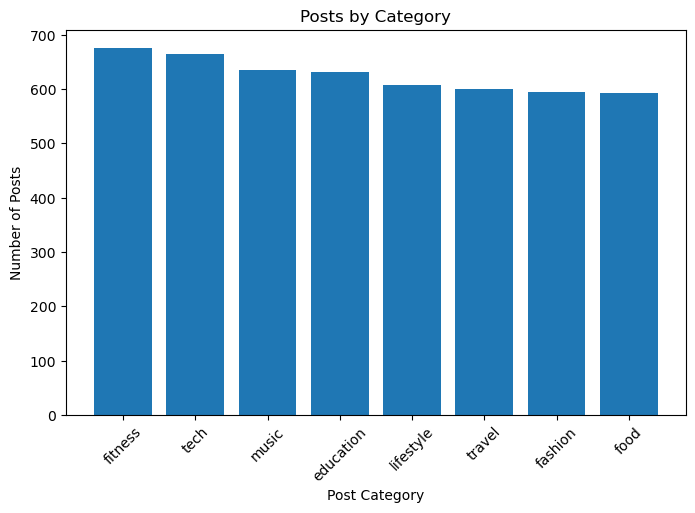

In [33]:
category_counts = df["post_category"].value_counts()

plt.figure(figsize=(8,5))
plt.bar(category_counts.index, category_counts.values)
plt.xlabel("Post Category")
plt.ylabel("Number of Posts")
plt.title("Posts by Category")
plt.xticks(rotation=45)
plt.show()


In [ ]:
#Fitness has the highest number of posts, followed by tech and music, while food has the lowest number of posts.

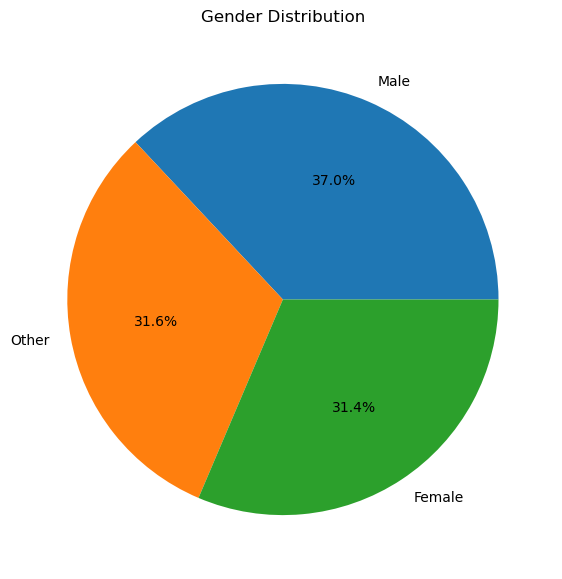

In [34]:
gender_counts = df["gender"].value_counts()

plt.figure(figsize=(7,7))
plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct="%1.1f%%"
)
plt.title("Gender Distribution")
plt.show()

In [ ]:
# This pie chart shows the distribution of users by gender.
# Male users represent approximately 37.0% of the dataset.
# Female users represent approximately 31.4%, while other users represent approximately 31.6%.
# The distribution is relatively balanced across the three groups.

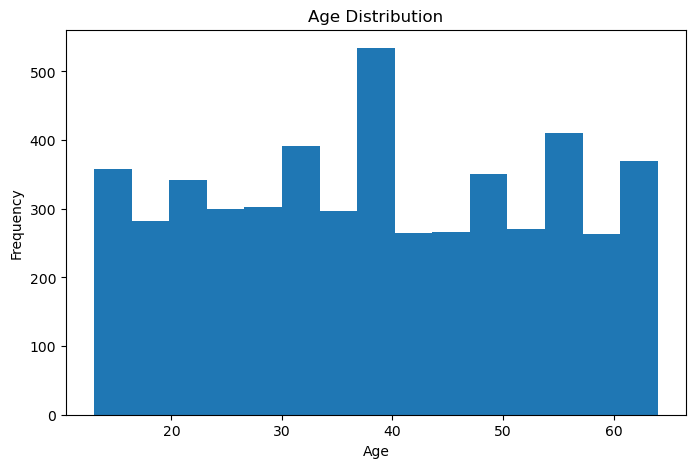

In [35]:
plt.figure(figsize=(8,5))
plt.hist(df["age"].dropna(), bins=15)
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Age Distribution")
plt.show()

In [ ]:
# This histogram shows the distribution of users' ages.
# The dataset contains users across a broad age range, approximately from the mid-teens to the early 60s.
# The distribution is fairly spread out, with no single age group dominating the dataset.

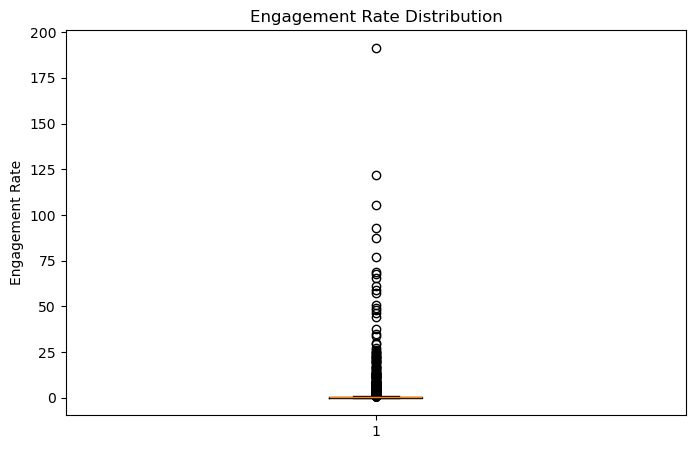

In [36]:
plt.figure(figsize=(8,5))
plt.boxplot(df["engagement_rate"].dropna())
plt.ylabel("Engagement Rate")
plt.title("Engagement Rate Distribution")
plt.show()


In [ ]:
# This boxplot shows the distribution of engagement rates.
# Most engagement rates are concentrated at relatively low values.
# Several extreme outliers can be seen at much higher engagement rates.
# This indicates that a small number of posts perform exceptionally well compared with most posts.

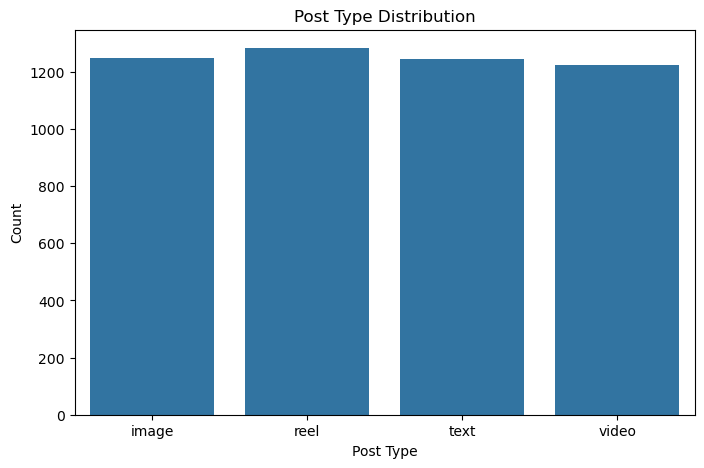

In [37]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="post_type")
plt.xlabel("Post Type")
plt.ylabel("Count")
plt.title("Post Type Distribution")
plt.show()

In [ ]:
# This bar chart shows the number of posts for each post type.
# Image, reel, text, and video posts have relatively similar counts.
# Reels have the highest count, while video posts have the lowest count among the four types.
# The relatively balanced distribution allows comparison of engagement across post types.

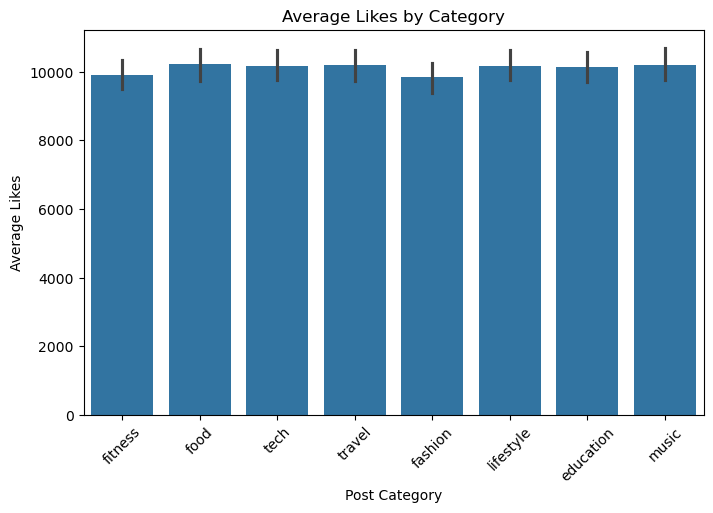

In [38]:
plt.figure(figsize=(8,5))
sns.barplot(data=df, x="post_category", y="likes")
plt.xlabel("Post Category")
plt.ylabel("Average Likes")
plt.title("Average Likes by Category")
plt.xticks(rotation=45)
plt.show()


In [ ]:
# This bar chart compares the average number of likes received by each content category.
# The average likes are relatively similar across categories.
# Food has the highest average likes, while fitness has the lowest among the categories shown.
# This shows that a category with fewer posts can still achieve a high average number of likes.

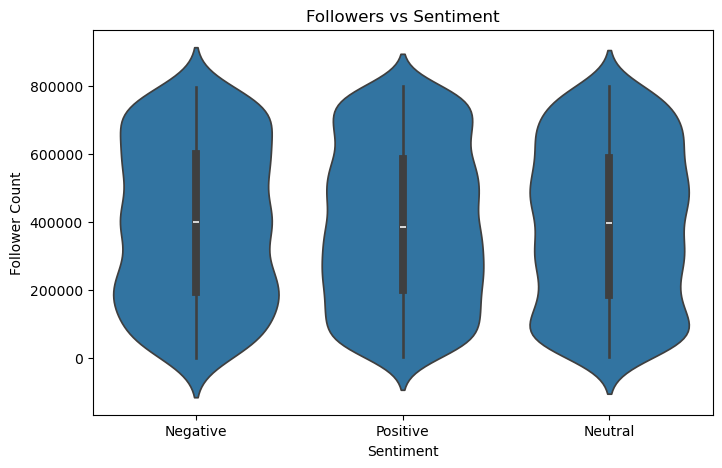

In [39]:
plt.figure(figsize=(8,5))

sns.violinplot(
    data=df,
    x="sentiment",
    y="follower_count"
)

plt.xlabel("Sentiment")
plt.ylabel("Follower Count")
plt.title("Followers vs Sentiment")
plt.show()


In [ ]:
# This violin plot compares follower counts across negative, positive, and neutral sentiment posts.
# The distributions are broadly similar across all three sentiment groups.
# Follower counts vary widely within each sentiment category.
# Therefore, sentiment does not appear to create a major difference in follower-count distribution.

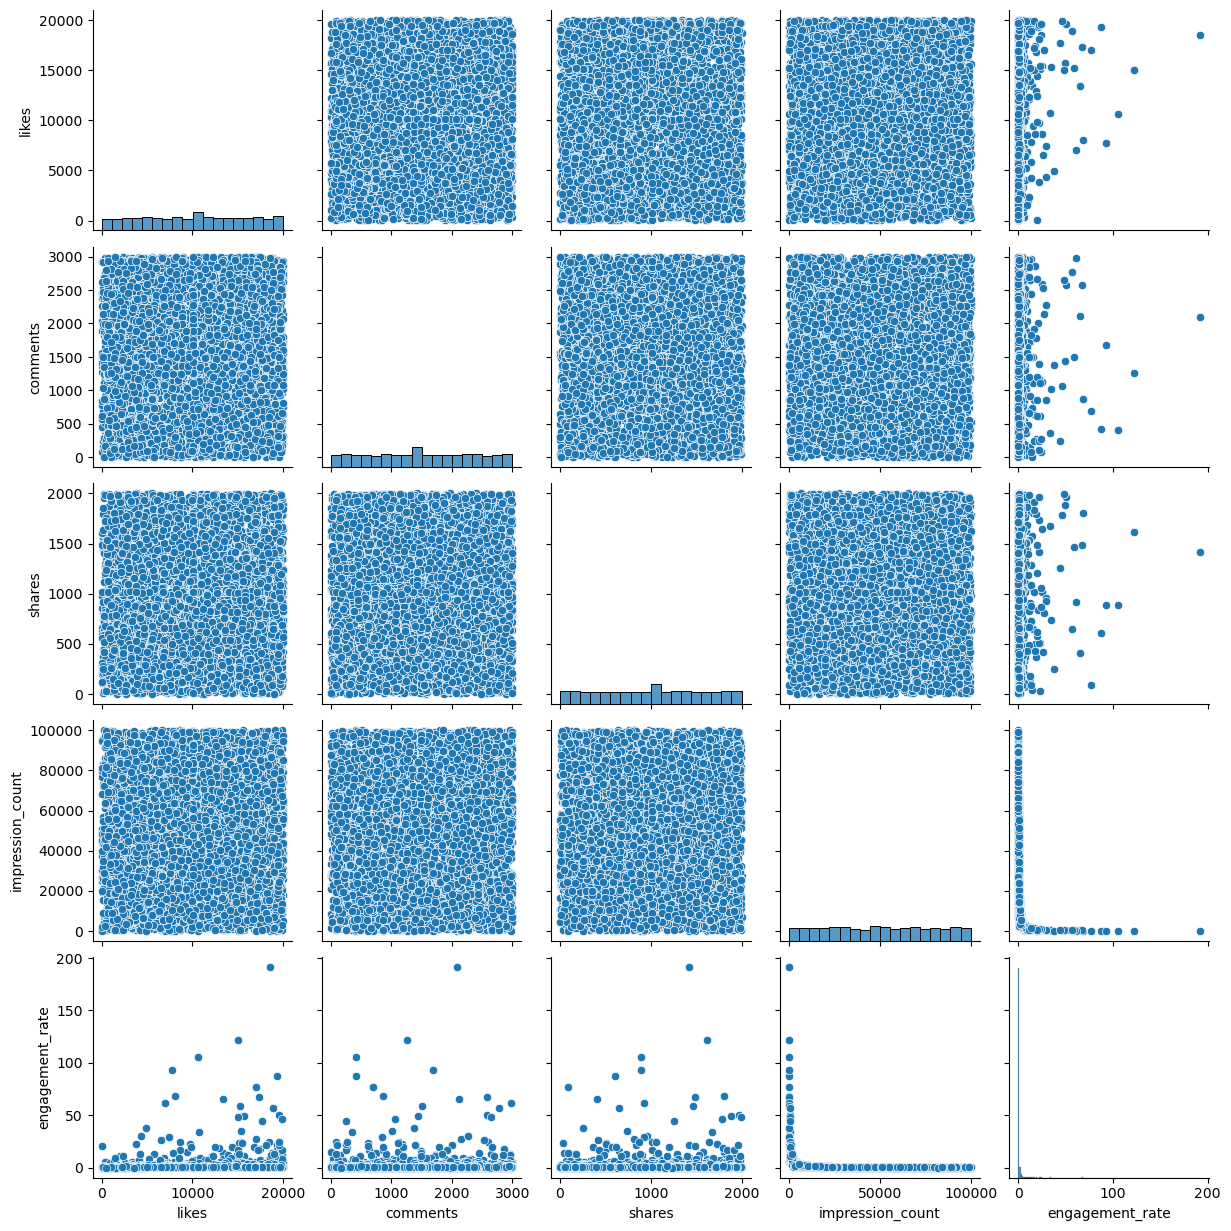

In [40]:
numeric_cols = [
    "likes",
    "comments",
    "shares",
    "impression_count",
    "engagement_rate"
]

sns.pairplot(df[numeric_cols].dropna())
plt.show()

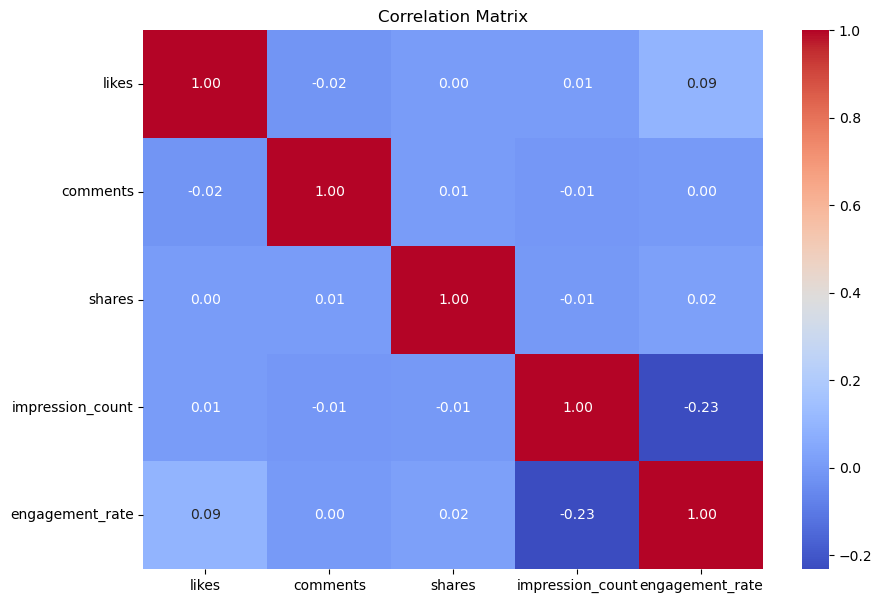

In [41]:
plt.figure(figsize=(10,7))

corr = df[numeric_cols].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [ ]:
# This heatmap shows the correlations between likes, comments, shares, impressions, and engagement rate.
# Most correlations between likes, comments, shares, and impressions are close to zero.
# Engagement rate has a weak negative correlation with impressions
# Overall the variables do not show strong linear relationships with one another.

C:\Users\HP\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 21.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\HP\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 14.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


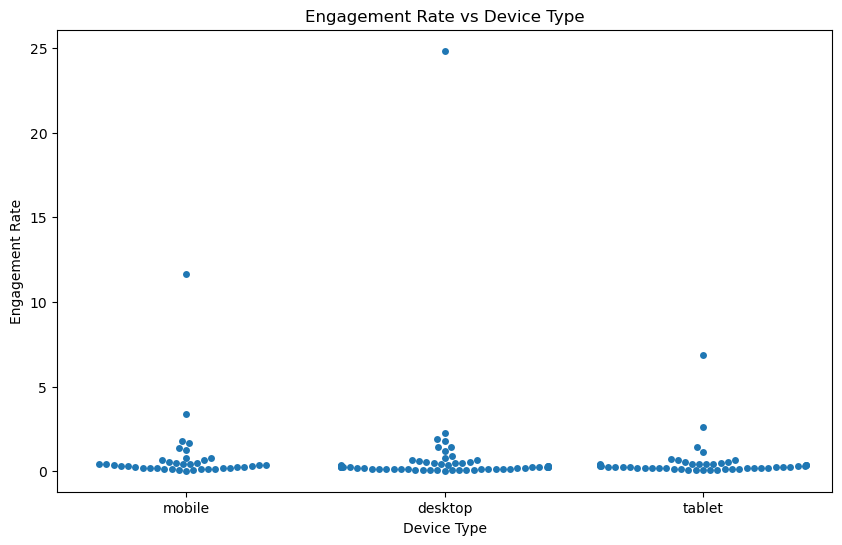

In [7]:
sample_df = df.sample(150, random_state=42)

plt.figure(figsize=(10,6))

sns.swarmplot(
    data=sample_df,
    x="device_type",
    y="engagement_rate"
)

plt.xlabel("Device Type")
plt.ylabel("Engagement Rate")
plt.title("Engagement Rate vs Device Type")
plt.show()

In [ ]:
# This graph compares engagement rates across mobile, desktop, and tablet devices.
# Most observations are concentrated at relatively low engagement rates.
# Mobile shows several high-engagement outliers, including the highest visible value.
# This suggests that while typical engagement is similar, some mobile posts achieve unusually high engagement.

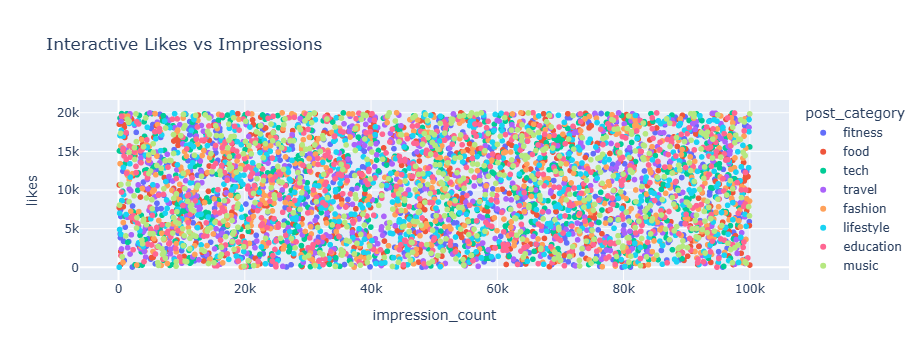

In [8]:
import plotly.express as px

fig = px.scatter(
    df,
    x="impression_count",
    y="likes",
    color="post_category",
    hover_data=["country", "post_type", "sentiment"],
    title="Interactive Likes vs Impressions"
)

fig.show()


In [ ]:
#No stronger relationship shown in the scatter plot

In [9]:
# Which post types have the highest engagement?

post_type_engagement = df.groupby("post_type")["engagement_rate"].mean().sort_values(ascending=False)

print(post_type_engagement)

post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64


In [10]:
# What is the best-performing content category?

category_engagement = df.groupby("post_category")["engagement_rate"].mean().sort_values(ascending=False)

print(category_engagement)

post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64


In [11]:
# Which countries have the highest average engagement rate?

country_engagement = df.groupby("country")["engagement_rate"].mean().sort_values(ascending=False)

print(country_engagement.head(5))

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
Name: engagement_rate, dtype: float64


In [12]:
# How does age affect engagement?

age_engagement_corr = df["age"].corr(df["engagement_rate"])

print("Correlation between age and engagement rate:", age_engagement_corr)

Correlation between age and engagement rate: 0.008044228514010468


In [13]:
# What is the performance difference for verified accounts?

verified_engagement = df.groupby("is_verified")["engagement_rate"].mean()

print(verified_engagement)

is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64


In [15]:
# What is the best time of day for impressions?

df["posted_at"] = pd.to_datetime(df["posted_at"], errors="coerce")

df["day_of_week"] = df["posted_at"].dt.day_name()

day_impressions = df.groupby("day_of_week")["impression_count"].mean().sort_values(ascending=False)

print(day_impressions)

day_of_week
Tuesday      51308.589849
Saturday     50945.228095
Sunday       50345.670782
Monday       50013.224928
Wednesday    49857.990000
Friday       49430.537827
Thursday     48119.289398
Name: impression_count, dtype: float64


C:\Users\HP\AppData\Local\Temp\ipykernel_13352\2595179822.py:3: UserWarning:

Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.



In [16]:
# What is the impact of device type on watch time?

device_watch_time = df.groupby("device_type")["watch_time_sec"].mean().sort_values(ascending=False)

print(device_watch_time)

device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64


In [17]:
# Which sentiment performs best?

sentiment_performance = df.groupby("sentiment")["engagement_rate"].mean().sort_values(ascending=False)

print(sentiment_performance)


sentiment
negative    1.038486
neutral     0.991170
positive    0.954800
Name: engagement_rate, dtype: float64


In [22]:
# Behavior of negative and neutral sentiment posts

sentiment_behavior = df[df["sentiment"].isin(["negative", "neutral"])].groupby("sentiment")[[
    "likes", "comments", "shares", "impression_count", "engagement_rate"
]].mean()

print(sentiment_behavior)

                  likes     comments       shares  impression_count  \
sentiment                                                             
negative   10211.406452  1516.584402  1007.186966      50191.960417   
neutral     9917.785570  1529.270525   996.149966      49515.971185   

           engagement_rate  
sentiment                   
negative          1.038486  
neutral           0.991170  


In [ ]:
#The analysis indicates that content format and category are more useful indicators of engagement than demographic variables such as age. 

#Video posts and tech content achieve the highest average engagement rates while Brazil has the highest countrylevel engagement.

# Verified accounts perform slightly better than non verified accounts and mobile users have the highest average watch time. 


#Tuesday is the strongest day for average impressions. Sentiment also shows an interesting pattern, with negative posts achieving the highest average engagement rate.

# Finally, the large number of engagement outliers suggests that individual high performing posts can have a substantial impact on overall results.
